# 7 · Profit rates across the EU, from AMECO

This notebook measures the rate of surplus value `e`, the organic composition `k` and the rate of profit `r` for the 27 EU member states and the EU27 aggregate, 1995–2024, from the European Commission's AMECO database. **It runs offline**: it reads the static extract `data/ameco_eu27.csv`, built by `data/build_ameco_eu.jl` with the package's own SDMX downloader and with the Commission's forecast years removed. Provenance and the licence terms are in `data/ameco_eu27_PROVENANCE.md`.

The mapping is the one `analyze_time_series_with_data` uses: compensation of employees → `V`, the net capital stock → `C`, value added less `V` and depreciation → surplus value. So `e = (Y − V − D)/V`, `k = C/V` and `r = (Y − V − D)/(C + V)`, with `r = e/(1 + k)` exactly.

Two measurement choices change the answers, and both are made explicit below: whether the self-employed count as workers, and the prices at which `C` and `V` are compared.

> Source: European Commission, DG ECFIN, AMECO database, 2026 release.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, StatsPlots, DataFrames, Statistics, Random
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

In [2]:
"""One AMECOData per area, from the static extract."""
function load_area(raw, area)
    d = sort(raw[raw.country .== area, :], :year)
    s = Dict(String(n) => [ismissing(x) ? NaN : Float64(x) for x in d[!, n]] for n in names(raw)[4:end])
    return build_ameco_data(_resolve_country_code(area), collect(Int, d.year), s,
                            "AMECO extract (data/ameco_eu27.csv)")
end

"""Value of a measure (`:e`, `:k`, `:r`, `:wage_share`) for one area and year."""
at(ts, a, field, y) = getfield(ts[a], field)[findfirst(==(y), ts[a].years)]

"""The years `lo:hi` of one measure, as (years, values)."""
function window(ts, a, field, lo, hi)
    ys = ts[a].years
    m = (ys .>= lo) .& (ys .<= hi)
    return ys[m], getfield(ts[a], field)[m]
end

"""OLS slope of x on the year, over the years where x is finite."""
function trend(years, x)
    ok = isfinite.(x)
    t, v = years[ok], x[ok]
    return sum((t .- mean(t)) .* (v .- mean(v))) / sum(abs2, t .- mean(t))
end

"""Exact split of the change in ln r between two years:
r = e / (1 + k), so Δ ln r = Δ ln e − Δ ln(1 + k)."""
function decompose(ts, a, lo, hi)
    ys, r = window(ts, a, :r, lo, hi); _, e = window(ts, a, :e, lo, hi); _, k = window(ts, a, :k, lo, hi)
    i, j = findfirst(isfinite, r), findlast(isfinite, r)
    return (country = a, dln_r = log(r[j] / r[i]),
            from_e = log(e[j] / e[i]), from_k = -log((1 + k[j]) / (1 + k[i])))
end

rounded(df, cols, d) = transform(df, cols .=> (x -> round.(x, digits = d)) .=> cols)
showall(df) = (show(stdout, df; allrows = true, eltypes = false, summary = false); println())

showall (generic function with 1 method)

## 1. The extract

`build_ameco_data` turns each area's columns into an `AMECOData`, the structure the rest of the package takes. Monetary values are in national currency, so countries are compared only through ratios.

The self-employed are handled in the measures, not in the data: `self_employed = :imputed` scales compensation by total employment over employees, so each self-employed worker is counted as earning the average employee's wage. AMECO's own adjusted wage share makes the same imputation.

In [3]:
raw = CSV.read(joinpath("..", "..", "data", "ameco_eu27.csv"), DataFrame)
areas = String.(unique(raw.country))
countries = filter(!=("European Union (27)"), areas)
eu = Dict(a => load_area(raw, a) for a in areas)
(areas = length(areas), years = extrema(raw.year), series = length(names(raw)) - 3)

(areas = 28, years = (1995, 2025), series = 26)

## 2. Measures, on one price basis

AMECO's net capital stock is at constant 2020 prices; compensation and value added are at current prices. `valuation = :consistent` deflates `V` and depreciation by the GDP deflator, which leaves `e` and the wage share exactly as they are at current prices and puts `C` and `V` on one basis for `k` and `r`. Section 7 shows what happens without it.

In [4]:
# e, k, r and the wage share, year by year. :consistent deflates V and the
# depreciation by the GDP deflator, so C (constant prices) and V are on one
# basis, while e and the wage share keep their current-price values exactly.
ts     = Dict(a => analyze_time_series_with_data(eu[a]; valuation = :consistent,
                                                 self_employed = :imputed) for a in areas)
ts_raw = Dict(a => analyze_time_series_with_data(eu[a]; valuation = :consistent) for a in areas)

# The capital stock is the series that ends first; use the years every area has.
lo = maximum(minimum(ts[a].years[isfinite.(ts[a].r)]) for a in areas)
hi = minimum(maximum(ts[a].years[isfinite.(ts[a].r)]) for a in areas)
(first_year = lo, last_year = hi)

(first_year = 1995, last_year = 2024)

The capital stock ends in 2024 for some countries, so the common window is 1995–2024.

## 3. The self-employed

Compensation of employees leaves out the self-employed. Without an adjustment, their income counts as surplus value, and `e` is overstated wherever self-employment is common.

In [5]:
se = DataFrame(country = countries,
               e_published = [at(ts_raw, a, :e, hi) for a in countries],
               e_adjusted  = [at(ts, a, :e, hi) for a in countries],
               self_employed_pct = [100 * (1 - (i = findfirst(==(hi), eu[a].years); eu[a].employees[i] / eu[a].employment[i]))
                                     for a in countries])
showall(sort(rounded(se, ["e_published", "e_adjusted", "self_employed_pct"], 2), :self_employed_pct, rev = true))

 Row │ country      e_published  e_adjusted  self_employed_pct 
─────┼─────────────────────────────────────────────────────────
   1 │ Greece              1.44        0.79              26.4
   2 │ Bulgaria            0.95        0.48              24.06
   3 │ Italy               1.09        0.61              22.99
   4 │ Romania             1.03        0.59              22.08
   5 │ Slovenia            0.59        0.27              20.08
   6 │ Poland              1.16        0.74              19.26
   7 │ Belgium             0.66        0.37              17.53
   8 │ Netherlands         0.8         0.49              17.08
   9 │ Portugal            0.72        0.46              15.2
  10 │ Slovakia            0.96        0.68              14.4
  11 │ Czechia             0.79        0.53              14.34
  12 │ Spain               0.77        0.51              14.33
  13 │ Malta               1.1         0.81              13.86
  14 │ Ireland             1.79        1.42             

The adjustment matters most where small farms, shops and trades are common. In Greece, where 26% of the employed are self-employed, `e` falls from 1.44 to 0.79; in Italy from 1.09 to 0.61; in Poland from 1.16 to 0.74. In Sweden, at 5%, it moves from 0.69 to 0.60. The published series ranks Greece above Germany by a factor of three; the adjusted one by a factor of two. Everything from here on uses the adjusted series.

## 4. The member states in 2024

In [6]:
tbl = DataFrame(country = countries,
                e = [at(ts, a, :e, hi) for a in countries],
                k = [at(ts, a, :k, hi) for a in countries],
                r_pct = [100 * at(ts, a, :r, hi) for a in countries],
                wage_share_pct = [100 * at(ts, a, :wage_share, hi) for a in countries])
showall(sort(rounded(tbl, ["e", "k", "r_pct", "wage_share_pct"], 2), :r_pct, rev = true))

 Row │ country      e     k     r_pct  wage_share_pct 
─────┼────────────────────────────────────────────────
   1 │ Ireland      1.42  4.99  23.66           31.43
   2 │ Slovakia     0.68  2.77  17.96           49.71
   3 │ Malta        0.81  3.54  17.73           48.55
   4 │ Poland       0.74  3.74  15.64           51.24
   5 │ Cyprus       0.81  4.6   14.39           49.13
   6 │ Luxembourg   0.63  4.28  11.9            53.22
   7 │ Romania      0.59  3.94  11.85           53.65
   8 │ Hungary      0.7   4.96  11.75           47.05
   9 │ Lithuania    0.56  3.8   11.59           55.91
  10 │ Croatia      0.56  3.85  11.56           54.58
  11 │ Bulgaria     0.48  3.89   9.79           59.89
  12 │ Denmark      0.51  4.46   9.36           54.36
  13 │ Netherlands  0.49  4.55   8.82           56.48
  14 │ Greece       0.79  8.03   8.8            48.42
  15 │ Italy        0.61  6.15   8.48           51.13
  16 │ Czechia      0.53  5.39   8.29           50.86
  17 │ Latvia       0.38  

Ireland is at the top with `r` = 23.7%, and that number says more about tax law than about exploitation: the profits of multinationals that book their intellectual property in Ireland are in its value added. Leave it aside and the top of the table is Central and Eastern Europe: Slovakia 18.0%, Malta 17.7%, Poland 15.6%. The bottom is the old industrial core: Austria 5.5%, Germany 6.0%, France 6.4%, Belgium 6.6%.

## 5. The EU27 over thirty years

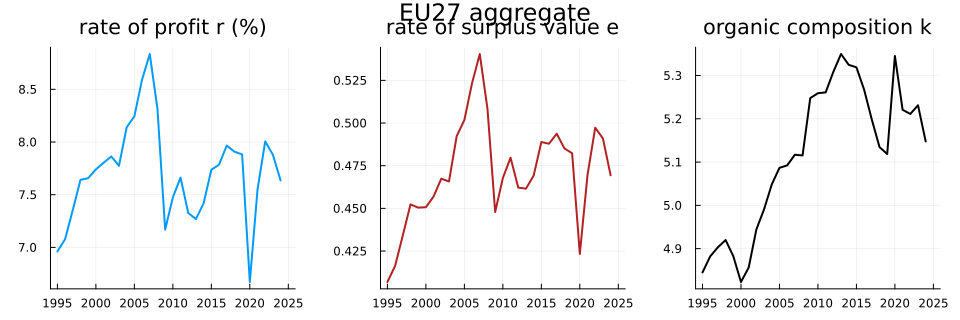

(first = (1995, (r = 6.96, e = 0.407, k = 4.84)), lowest = (2020, (r = 6.67, e = 0.423, k = 5.35)), last = (2024, (r = 7.64, e = 0.469, k = 5.15)))

In [7]:
eu27 = ts["European Union (27)"]
p1 = plot(eu27.years, 100 .* eu27.r, lw = 2, label = "", title = "rate of profit r (%)")
p2 = plot(eu27.years, eu27.e, lw = 2, label = "", color = :firebrick, title = "rate of surplus value e")
p3 = plot(eu27.years, eu27.k, lw = 2, label = "", color = :black, title = "organic composition k")
display(plot(p1, p2, p3, layout = (1, 3), size = (960, 320), plot_title = "EU27 aggregate"))
yr(y) = (r = round(100 * at(ts, "European Union (27)", :r, y), digits = 2),
         e = round(at(ts, "European Union (27)", :e, y), digits = 3),
         k = round(at(ts, "European Union (27)", :k, y), digits = 2))
imin = argmin(replace(eu27.r, NaN => Inf))
(first = (lo, yr(lo)), lowest = (eu27.years[imin], yr(eu27.years[imin])), last = (hi, yr(hi)))

For the EU27 aggregate, `r` was 6.96% in 1995, peaked before the financial crisis, reached its low of 6.67% in 2020 and was 7.64% in 2024. Over the whole period `e` rose from 0.41 to 0.47 and `k` from 4.84 to 5.15.

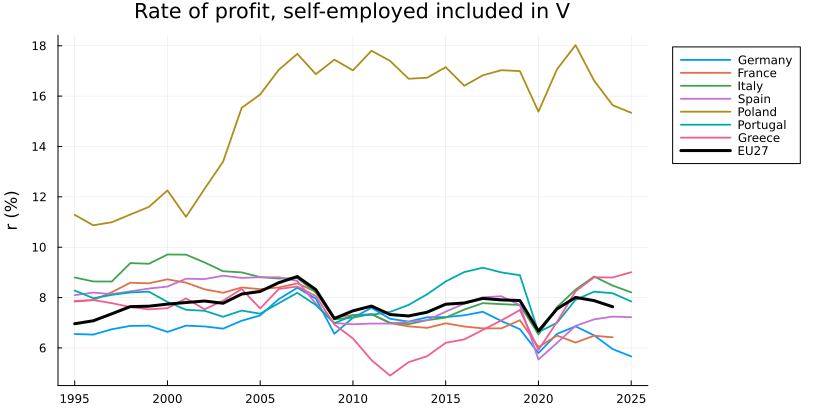

In [8]:
pick = ["Germany", "France", "Italy", "Spain", "Poland", "Portugal", "Greece"]
plt = plot(title = "Rate of profit, self-employed included in V", ylabel = "r (%)",
           legend = :outertopright, size = (820, 420))
for a in pick
    plot!(plt, ts[a].years, 100 .* ts[a].r, lw = 1.8, label = a)
end
plot!(plt, eu27.years, 100 .* eu27.r, lw = 3, color = :black, label = "EU27")
plt

Poland's rate of profit rose from about 11% in 2001 to 17–18% by 2007 and has stayed between 15% and 18% since, about twice the EU27 level. Greece fell from about 7.5% in 2008 to 4.9% in 2012, in the depression, and recovered to 9% by 2025. The other large economies stay within a band of 6–9% and move together, with common falls in 2009 and 2020. Some lines run to 2025, where a country's capital stock does.

## 6. Is the rate of profit falling?

The trend is the OLS slope over 1995–2024, in percentage points per decade.

In [9]:
slope(a, f) = trend(window(ts, a, f, lo, hi)...)
trends = DataFrame(country = countries,
                   r_pp_per_decade = [1000 * slope(a, :r) for a in countries],
                   e_per_decade    = [10 * slope(a, :e) for a in countries],
                   k_per_decade    = [10 * slope(a, :k) for a in countries])
println("rate of profit falling in ", count(<(0), trends.r_pp_per_decade), " of ",
        nrow(trends), " countries, $lo-$hi; EU27 aggregate: ",
        round(1000 * slope("European Union (27)", :r), digits = 2), " pp per decade\n")
showall(sort(rounded(trends, ["r_pp_per_decade", "e_per_decade", "k_per_decade"], 2), :r_pp_per_decade))

rate of profit falling in 18

 of 27 countries, 1995-2024; EU27 aggregate: 0.02 pp per decade

 Row │ country      r_pp_per_decade  e_per_decade  k_per_decade 
─────┼──────────────────────────────────────────────────────────
   1 │ Bulgaria               -3.54         -0.24         -0.29
   2 │ Estonia                -2.44         -0.06          0.61
   3 │ Latvia                 -1.94         -0.06          0.15
   4 │ France                 -0.85         -0.05          0.11
   5 │ Luxembourg             -0.71         -0.01          0.19
   6 │ Spain                  -0.66          0.01          0.72
   7 │ Italy                  -0.64         -0.02          0.3
   8 │ Lithuania              -0.58         -0.02          0.06
   9 │ Sweden                 -0.47         -0.06         -0.28
  10 │ Finland                -0.37         -0.02          0.09
  11 │ Slovenia               -0.28         -0.02         -0.06
  12 │ Greece                 -0.27         -0.01          0.26
  13 │ Austria                -0.24   

**By trend, the rate of profit fell in 18 of 27 countries, but the EU27 aggregate is flat: +0.02 percentage points per decade.** The falls are concentrated in three of the Baltic and Balkan economies (Bulgaria −3.5, Estonia −2.4, Latvia −1.9), and in the core they are small (France −0.85, Germany −0.08). The largest rises are in Romania (+3.5), Ireland (+3.0), Slovakia (+2.5) and Poland (+2.2). The aggregate is not an average of the country trends: it is computed from EU27 totals, in which each country weighs by its size in euros.

### Exploitation or composition?

Because `r = e/(1 + k)`, the change in `ln r` between two years splits exactly into `Δ ln e` and `−Δ ln(1 + k)`. The first is the contribution of the rate of surplus value, the second of the organic composition. Marx's law says the second should be negative and the first, a counteracting tendency, may offset it.

In [10]:
dec = sort(DataFrame([decompose(ts, a, lo, hi) for a in areas]), :dln_r)
showall(rounded(dec, ["dln_r", "from_e", "from_k"], 3))
m = dec.country .!= "European Union (27)"
println("
of 27 countries: r fell in ", count(<(0), dec.dln_r[m]), "; e fell in ", count(<(0), dec.from_e[m]),
        "; k rose (from_k < 0) in ", count(<(0), dec.from_k[m]),
        "; |from_e| > |from_k| in ", count(abs.(dec.from_e[m]) .> abs.(dec.from_k[m])))

 Row │ country              dln_r   from_e  from_k 
─────┼─────────────────────────────────────────────
   1 │ Bulgaria             -0.865  -1.1     0.235
   2 │ Estonia              -0.438  -0.16   -0.279
   3 │ Latvia               -0.214  -0.309   0.095
   4 │ France               -0.2    -0.176  -0.024
   5 │ Sweden               -0.17   -0.279   0.109
   6 │ Lithuania            -0.159  -0.273   0.113
   7 │ Czechia              -0.153  -0.346   0.193
   8 │ Luxembourg           -0.124  -0.068  -0.055
   9 │ Austria              -0.116  -0.058  -0.057
  10 │ Spain                -0.111   0.083  -0.195
  11 │ Germany              -0.096  -0.138   0.043
  12 │ Denmark              -0.052  -0.028  -0.024
  13 │ Hungary              -0.04    0.141  -0.181
  14 │ Italy                -0.037   0.052  -0.089
  15 │ Belgium              -0.035   0.001  -0.036
  16 │ Portugal             -0.013   0.065  -0.078
  17 │ Finland               0.054   0.048   0.006
  18 │ European Union (27)   


of 27 countries: r fell in 16

; e fell in 11; k rose (from_k < 0) in 15; |from_e| > |from_k| in 20


The organic composition rose, pulling the rate of profit down, in 15 of 27 countries and in the EU27 aggregate. But **the change in `e` was larger than the change from `k` in 20 of 27 countries.** Where the rate of profit fell, it fell mostly because `e` fell: Bulgaria (−1.10 from `e`, +0.24 from `k`), Latvia, Sweden, Lithuania, Czechia, Germany. Wages there rose faster than the surplus. Composition was the main drag in Estonia, where both fell, and in Spain, Hungary, Italy, Portugal and Belgium, where `e` rose and a rising `k` more than offset it. In Austria the two are about equal.

For the EU27 aggregate, `Δ ln r` = +0.092 = +0.143 from `e` − 0.050 from `k`: a rising organic composition pulled the rate of profit down, and a rising rate of surplus value more than offset it. That is the law with its counteracting tendency winning, over these thirty years.

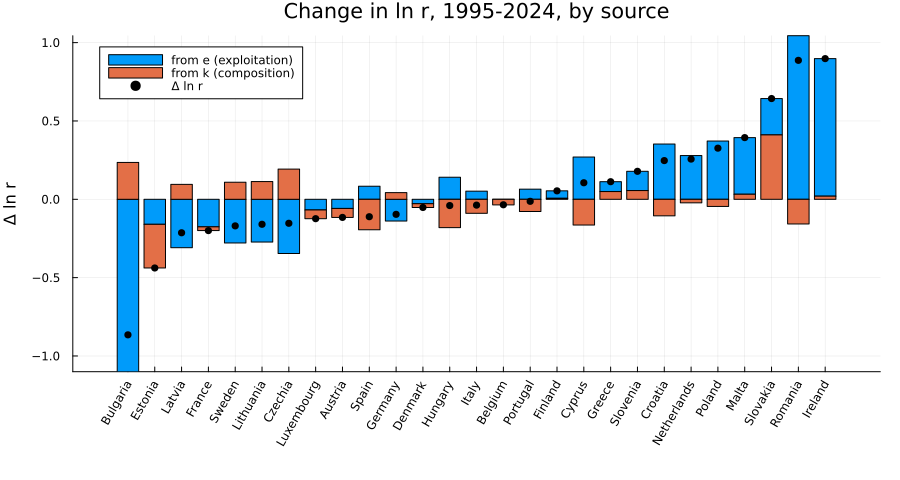

In [11]:
d = filter(:country => !=("European Union (27)"), dec)
groupedbar(d.country, [d.from_e d.from_k], bar_position = :stack,
           label = ["from e (exploitation)" "from k (composition)"], xrotation = 60,
           ylabel = "Δ ln r", size = (900, 480), bottom_margin = 14Plots.mm, title = "Change in ln r, $lo-$hi, by source")
scatter!(d.country, d.dln_r, color = :black, label = "Δ ln r", markersize = 4)

## 7. The valuation decides the trend in `k`

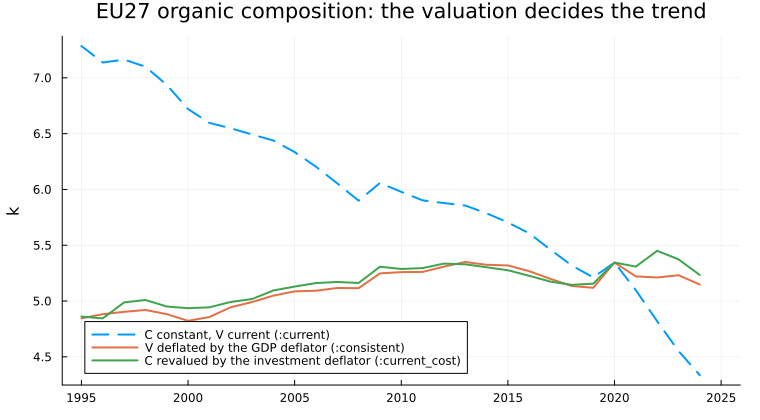

Dict{Symbol, Tuple{Float64, Float64}} with 3 entries:
  :current      => (7.28, 4.34)
  :consistent   => (4.84, 5.15)
  :current_cost => (4.86, 5.23)

In [12]:
k_val = Dict(v => analyze_time_series_with_data(eu["European Union (27)"]; valuation = v,
                                                 self_employed = :imputed).k
             for v in (:current, :consistent, :current_cost))
plot(eu27.years, k_val[:current], lw = 2, ls = :dash, label = "C constant, V current (:current)",
     title = "EU27 organic composition: the valuation decides the trend", ylabel = "k")
plot!(eu27.years, k_val[:consistent], lw = 2, label = "V deflated by the GDP deflator (:consistent)")
display(plot!(eu27.years, k_val[:current_cost], lw = 2, label = "C revalued by the investment deflator (:current_cost)"))
i, j = findfirst(==(lo), eu27.years), findfirst(==(hi), eu27.years)
Dict(v => (round(k_val[v][i], digits = 2), round(k_val[v][j], digits = 2)) for v in keys(k_val))

With `C` at constant prices and `V` at current prices (`:current`), the EU27 organic composition **falls by 40%**, from 7.28 to 4.34. On a consistent basis it **rises**, from 4.84 to 5.15 with the GDP deflator or to 5.23 at current cost, with the stock revalued by the investment deflator. The two consistent valuations differ only in the price index that puts `C` and `V` on one basis. The fall is wage inflation in the denominator, not a change in production. Any series of `k` built from AMECO's capital stock and current-price wages has this problem, and a reading of it as evidence against the law of the falling rate of profit is a reading of the deflator.

## 8. Across countries, `e` sets `r`

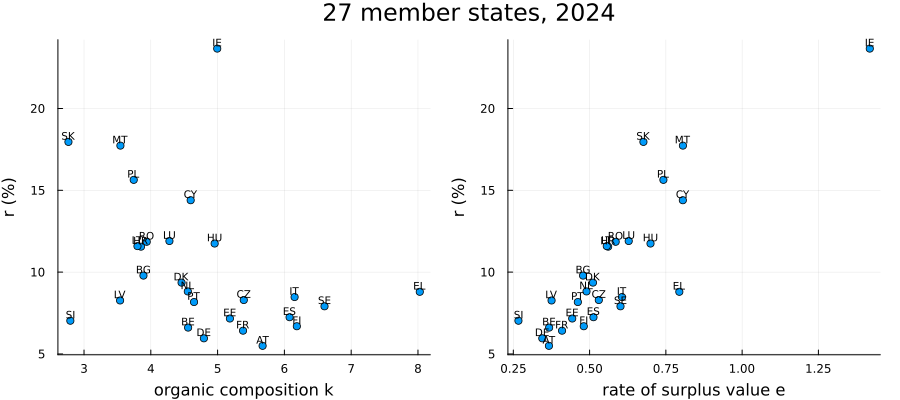

(corr_r_k = -0.38, corr_r_e = 0.86)

In [13]:
cs = DataFrame(code = [_resolve_country_code(a) for a in countries],
               e = [at(ts, a, :e, hi) for a in countries],
               k = [at(ts, a, :k, hi) for a in countries],
               r = [100 * at(ts, a, :r, hi) for a in countries])
p1 = scatter(cs.k, cs.r, xlabel = "organic composition k", ylabel = "r (%)", legend = false,
             series_annotations = text.(cs.code, 7, :bottom))
p2 = scatter(cs.e, cs.r, xlabel = "rate of surplus value e", ylabel = "r (%)", legend = false,
             series_annotations = text.(cs.code, 7, :bottom))
display(plot(p1, p2, layout = (1, 2), size = (900, 400), plot_title = "27 member states, $hi"))
(corr_r_k = round(cor(cs.k, cs.r), digits = 2), corr_r_e = round(cor(cs.e, cs.r), digits = 2))

In 2024, the correlation of `r` with `e` across the 27 member states is 0.86, and with `k` it is −0.38. Countries differ in their rate of profit mainly because they differ in the rate of surplus value, not in the composition of capital. Greece is the clearest exception: `k` = 8.0, the highest in the EU, and a middling `r`.

## 9. The real data in the model

`calibrate_with_ameco_data` takes any `AMECOData`, so the extract also feeds the model's three-department calibration, offline. It revalues AMECO's constant-price capital stock to current replacement cost with the investment deflator, and takes the same `self_employed` keyword as the measures above.

In [14]:
Random.seed!(7)   # the :fixed calibration draws a random technical matrix
cal = DataFrame(country = String[], e_calibrated = Float64[], k_calibrated = Float64[],
                e_series = Float64[], k_series = Float64[])
for a in ["Germany", "Portugal", "Poland"]
    params, _ = calibrate_with_ameco_data(eu[a], hi, :macro; self_employed = :imputed)
    cc = analyze_time_series_with_data(eu[a]; valuation = :current_cost, self_employed = :imputed)
    i = findfirst(==(hi), cc.years)
    push!(cal, (a, mean(params.e_raw), sum(params.C) / sum(params.V), cc.e[i], cc.k[i]))
end
showall(rounded(cal, ["e_calibrated", "k_calibrated", "e_series", "k_series"], 3))

CALIBRATION WITH AMECO DATA — Germany | Year: 2024
Source: AMECO extract (data/ameco_eu27.csv)
  ✓ self-employed imputed at the average employee's compensation (V × 1.088)

📊 Data (2024): GDP 4329.0 bn | Employment 45.99 M | Stock K 12871.8 bn (current prices)

📐 Marxian parameters:
  Primary: e=0.35 k=10.06 r=3.12%
  Secondary: e=0.35 k=2.68 r=9.37%
  Tertiary: e=0.35 k=5.98 r=4.94%

✅ CALIBRATION COMPLETE — mean e 0.35 | mean r 5.81%




CALIBRATION WITH AMECO DATA — Portugal | Year: 2024
Source: AMECO extract (data/ameco_eu27.csv)
  ✓ self-employed imputed at the average employee's compensation (V × 1.179)

📊 Data (2024): GDP 289.8 bn | Employment 5.28 M | Stock K 765.4 bn (current prices)

📐 Marxian parameters:
  Primary: e=0.46 k=4.7 r=8.09%
  Secondary: e=0.46 k=3.42 r=10.44%
  Tertiary: e=0.46 k=5.08 r=7.6%

✅ CALIBRATION COMPLETE — mean e 0.46 | mean r 8.71%


CALIBRATION WITH AMECO DATA — Poland | Year: 2024
Source: AMECO extract (data/ameco_eu27.csv)
  ✓ self-employed imputed at the average employee's compensation (V × 1.239)

📊 Data (2024): GDP 3669.5 bn | Employment 17.42 M | Stock K 6559.4 bn (current prices)

📐 Marxian parameters:
  Primary: e=0.74 k=3.49 r=16.53%
  Secondary: e=0.74 k=2.23 r=22.95%
  Tertiary: e=0.74 k=3.92 r=15.09%

✅ CALIBRATION COMPLETE — mean e 0.74 | mean r 18.19%

 Row │ country   e_calibrated  k_calibrated  e_series  k_series 
─────┼──────────────────────────────────────────────────

The calibration reproduces the time series exactly. `valuation = :current_cost` is its price basis: everything at current prices, with `C` revalued by the investment deflator, so `e` is the current-price rate and `k` is the current-cost one of section 7. Before the revaluation was added, the calibration divided the stock at 2020 prices by 2024 wages, and its `k` was 17–25% too low for these three countries: the error of section 7, in the model's inputs.